Empirical and Theoretical PMF:
 Tickets (x)  Empirical PMF  Theoretical PMF
           0         0.0919           0.0907
           1         0.2168           0.2177
           2         0.2628           0.2613
           3         0.2050           0.2090
           4         0.1261           0.1254
           5         0.0591           0.0602
           6         0.0254           0.0241
           7         0.0096           0.0083
           8         0.0027           0.0025
           9         0.0004           0.0007
          10         0.0002           0.0002

Mean and Variance:
Empirical Mean: 2.4046
Theoretical Mean: 2.4
Empirical Variance: 2.4424
Theoretical Variance: 2.4

Probability Calculations:
P(X = 0), Simulation: 0.0919
P(X = 0), Theory: 0.0907
P(X >= 5), Simulation: 0.0974
P(X >= 5), Theory: 0.0959

30-Minute Interval:
Lambda for 30 minutes: 7.199999999999999
P(X > 10), Simulation: 0.1124
P(X > 10), Theory: 0.1133

Binomial and Poisson PMF Comparison:
 x  Binomial PMF  

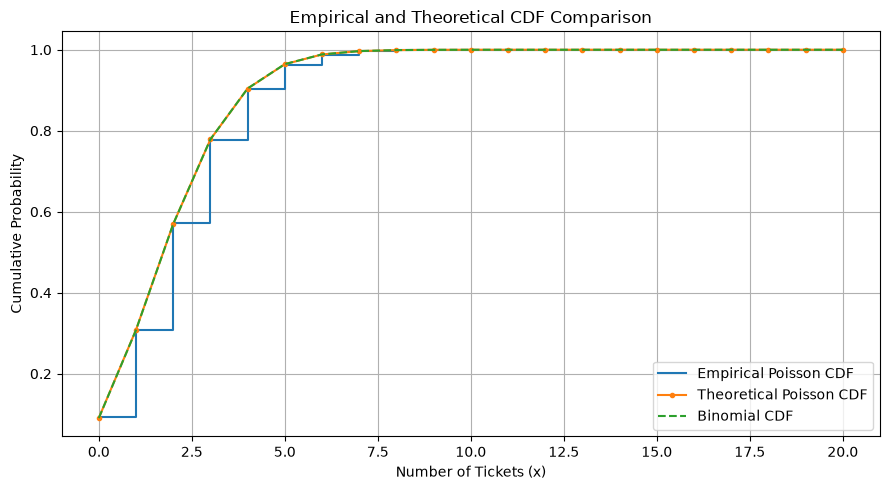

In [1]:
# 1. Import libraries
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

# 2. Define parameters
lam = 2.4
n = 20000

# 3. Simulate 20,000 intervals
rng = np.random.default_rng(42)
data = rng.poisson(lam, size=n)

# (a) Empirical and theoretical PMF for x = 0 to 10
x = np.arange(0, 11)

empirical_pmf = np.array([np.mean(data == i) for i in x])
theoretical_pmf = stats.poisson.pmf(x, lam)

pmf_table = pd.DataFrame({
    "Tickets (x)": x,
    "Empirical PMF": empirical_pmf,
    "Theoretical PMF": theoretical_pmf
})

print("Empirical and Theoretical PMF:")
print(pmf_table.round(4).to_string(index=False))

# (b) Compare empirical and theoretical mean and variance
emp_mean = np.mean(data)
emp_variance = np.var(data)

theoretical_mean = stats.poisson.mean(lam)
theoretical_variance = stats.poisson.var(lam)

print("\nMean and Variance:")
print("Empirical Mean:", round(emp_mean, 4))
print("Theoretical Mean:", theoretical_mean)
print("Empirical Variance:", round(emp_variance, 4))
print("Theoretical Variance:", theoretical_variance)

# (c) Calculate P(X = 0) and P(X >= 5)
sim_p_zero = np.mean(data == 0)
theory_p_zero = stats.poisson.pmf(0, lam)

sim_p_ge5 = np.mean(data >= 5)
theory_p_ge5 = stats.poisson.sf(4, lam)

print("\nProbability Calculations:")
print("P(X = 0), Simulation:", round(sim_p_zero, 4))
print("P(X = 0), Theory:", round(theory_p_zero, 4))
print("P(X >= 5), Simulation:", round(sim_p_ge5, 4))
print("P(X >= 5), Theory:", round(theory_p_ge5, 4))

# (d) Probability of more than 10 tickets in 30 minutes
lam_30 = 2.4 * 3

sim_30 = rng.poisson(lam_30, size=n)
sim_p_more10 = np.mean(sim_30 > 10)
theory_p_more10 = stats.poisson.sf(10, lam_30)

print("\n30-Minute Interval:")
print("Lambda for 30 minutes:", lam_30)
print("P(X > 10), Simulation:", round(sim_p_more10, 4))
print("P(X > 10), Theory:", round(theory_p_more10, 4))

# (e) Compare Binomial(1000, 0.0024) and Poisson(2.4)
N = 1000
p = 0.0024

x_compare = np.arange(0, 16)

binomial_pmf = stats.binom.pmf(x_compare, N, p)
poisson_pmf = stats.poisson.pmf(x_compare, lam)

comparison_table = pd.DataFrame({
    "x": x_compare,
    "Binomial PMF": binomial_pmf,
    "Poisson PMF": poisson_pmf
})

print("\nBinomial and Poisson PMF Comparison:")
print(comparison_table.round(6).to_string(index=False))

# Plot empirical and theoretical CDFs
x_cdf = np.arange(0, 21)

empirical_cdf = np.array([
    np.mean(data <= i) for i in x_cdf
])

poisson_cdf = stats.poisson.cdf(x_cdf, lam)
binomial_cdf = stats.binom.cdf(x_cdf, N, p)

plt.figure(figsize=(9, 5))

plt.step(
    x_cdf, empirical_cdf,
    where="post",
    label="Empirical Poisson CDF"
)

plt.plot(
    x_cdf, poisson_cdf,
    marker="o",
    markersize=3,
    label="Theoretical Poisson CDF"
)

plt.plot(
    x_cdf, binomial_cdf,
    linestyle="--",
    label="Binomial CDF"
)

plt.xlabel("Number of Tickets (x)")
plt.ylabel("Cumulative Probability")
plt.title("Empirical and Theoretical CDF Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()